# Giai đoạn 4: Trực quan hoá dữ liệu (Data Visualization)
**Dự án:** Phân tích dữ liệu thương mại điện tử Olist (Brazil, 2016–2018)

Notebook này minh hoạ bằng biểu đồ các phát hiện của Notebook 03. Mọi biểu đồ được lưu vào `reports/figures/` để dùng cho báo cáo và slide.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
PRO_DIR = '../data/processed/'
FIG_DIR = '../reports/figures/'
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f'{name}.png'), bbox_inches='tight')

master = pd.read_csv(os.path.join(PRO_DIR, 'olist_master.csv'),
                     dtype={'customer_zip_code_prefix': str, 'seller_zip_code_prefix': str},
                     parse_dates=['order_purchase_timestamp'])

# Bảng mức đơn hàng để không đếm lặp payment/review khi đơn có nhiều sản phẩm
orders = (master.groupby('order_id', as_index=False)
          .agg(customer_unique_id=('customer_unique_id', 'first'),
               customer_state=('customer_state', 'first'),
               customer_zip_code_prefix=('customer_zip_code_prefix', 'first'),
               purchase_ts=('order_purchase_timestamp', 'first'),
               year_month=('purchase_year_month', 'first'),
               weekday=('purchase_weekday', 'first'),
               hour=('purchase_hour', 'first'),
               n_items=('order_item_id', 'count'),
               product_value=('price', 'sum'),
               freight_value=('freight_value', 'sum'),
               payment_total=('payment_total', 'first'),
               payment_type=('payment_type', 'first'),
               payment_installments=('payment_installments', 'first'),
               delivery_days=('delivery_days', 'first'),
               estimated_days=('estimated_days', 'first'),
               delay_days=('delay_days', 'first'),
               is_late=('is_late', 'first'),
               review_score=('review_score', 'first'),
               same_state=('same_state', 'all')))
print(f'master: {master.shape[0]:,} dòng | orders: {orders.shape[0]:,} đơn')

master: 110,186 dòng | orders: 96,469 đơn


## 1. Doanh thu & số đơn theo tháng

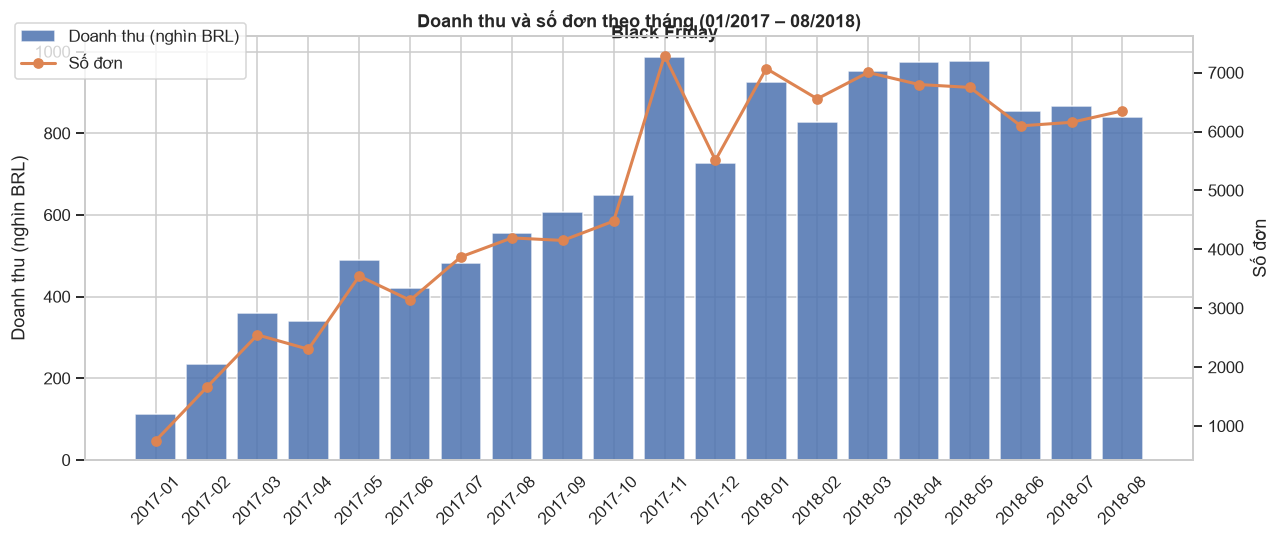

In [2]:
monthly = (orders[orders['year_month'] >= '2017-01']
           .groupby('year_month').agg(revenue=('product_value', 'sum'), n_orders=('order_id', 'count')))

fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.bar(monthly.index, monthly['revenue'] / 1e3, color='#4C72B0', alpha=0.85, label='Doanh thu (nghìn BRL)')
ax1.set_ylabel('Doanh thu (nghìn BRL)')
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly['n_orders'], color='#DD8452', marker='o', lw=2, label='Số đơn')
ax2.set_ylabel('Số đơn')
ax2.grid(False)
peak = monthly['revenue'].idxmax()
ax1.annotate('Black Friday', xy=(peak, monthly.loc[peak, 'revenue'] / 1e3), xytext=(0, 12),
             textcoords='offset points', ha='center', fontweight='bold')
ax1.set_title('Doanh thu và số đơn theo tháng (01/2017 – 08/2018)')
ax1.tick_params(axis='x', rotation=45)
fig.legend(loc='upper left', bbox_to_anchor=(0.07, 0.92))
save(fig, '01_monthly_revenue')
plt.show()

## 2. Thời điểm mua hàng (thứ × giờ)

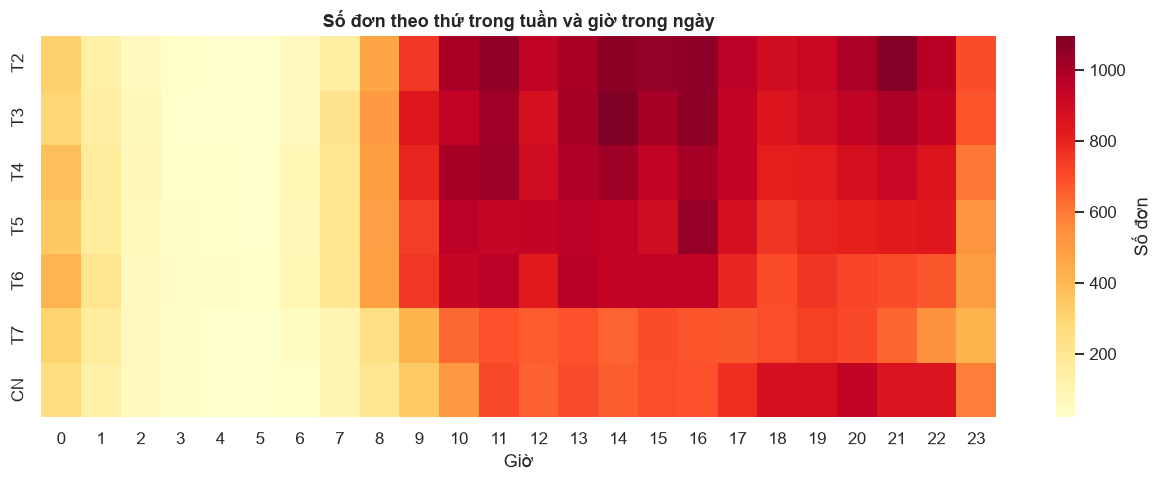

In [3]:
days = ['T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'CN']
heat = orders.pivot_table(index='weekday', columns='hour', values='order_id', aggfunc='count').rename(index=dict(enumerate(days)))

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(heat, cmap='YlOrRd', ax=ax, cbar_kws={'label': 'Số đơn'})
ax.set(title='Số đơn theo thứ trong tuần và giờ trong ngày', xlabel='Giờ', ylabel='')
save(fig, '02_weekday_hour_heatmap')
plt.show()

## 3. Top danh mục & đường Pareto

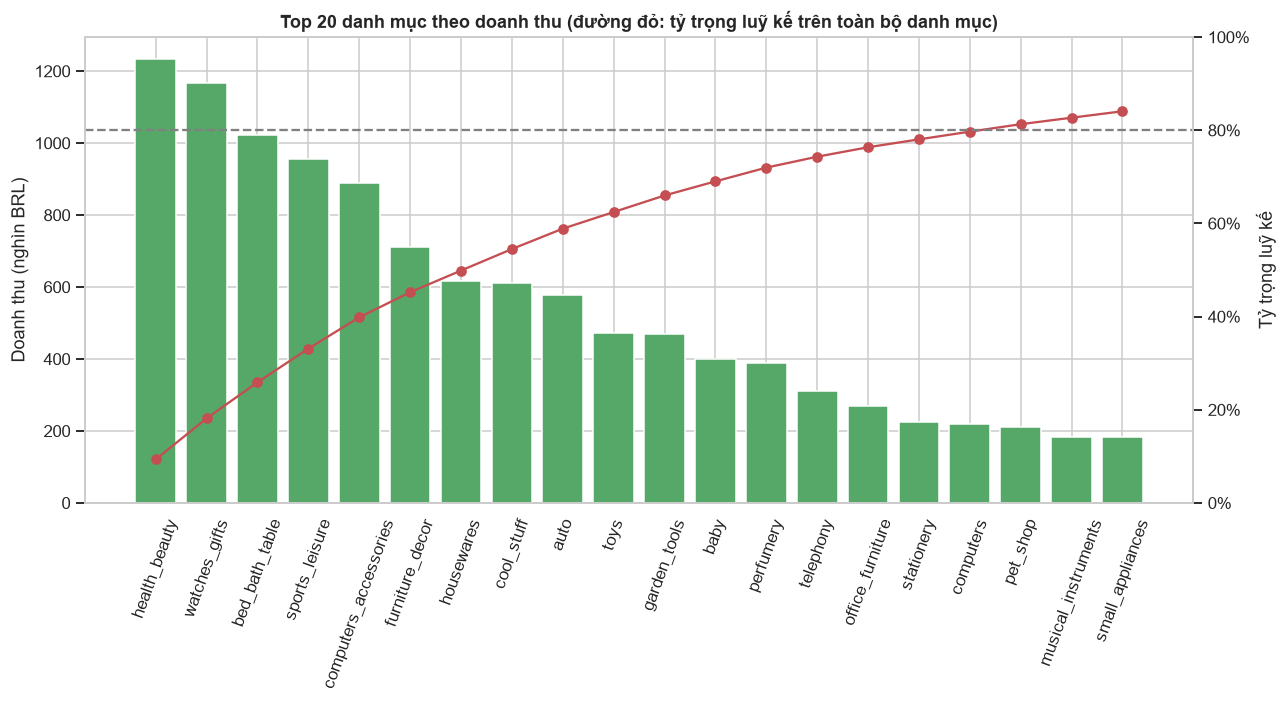

In [4]:
cat = master.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)
cum = cat.cumsum() / cat.sum() * 100
top = cat.head(20)

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(top.index, top / 1e3, color='#55A868')
ax.set_ylabel('Doanh thu (nghìn BRL)')
ax.tick_params(axis='x', rotation=70)
ax2 = ax.twinx()
ax2.plot(top.index, cum.head(20), color='#C44E52', marker='o')
ax2.axhline(80, ls='--', color='grey')
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.set_ylim(0, 100)
ax2.grid(False)
ax2.set_ylabel('Tỷ trọng luỹ kế')
ax.set_title('Top 20 danh mục theo doanh thu (đường đỏ: tỷ trọng luỹ kế trên toàn bộ danh mục)')
save(fig, '03_category_pareto')
plt.show()

## 4. Bang: số đơn và thời gian giao hàng

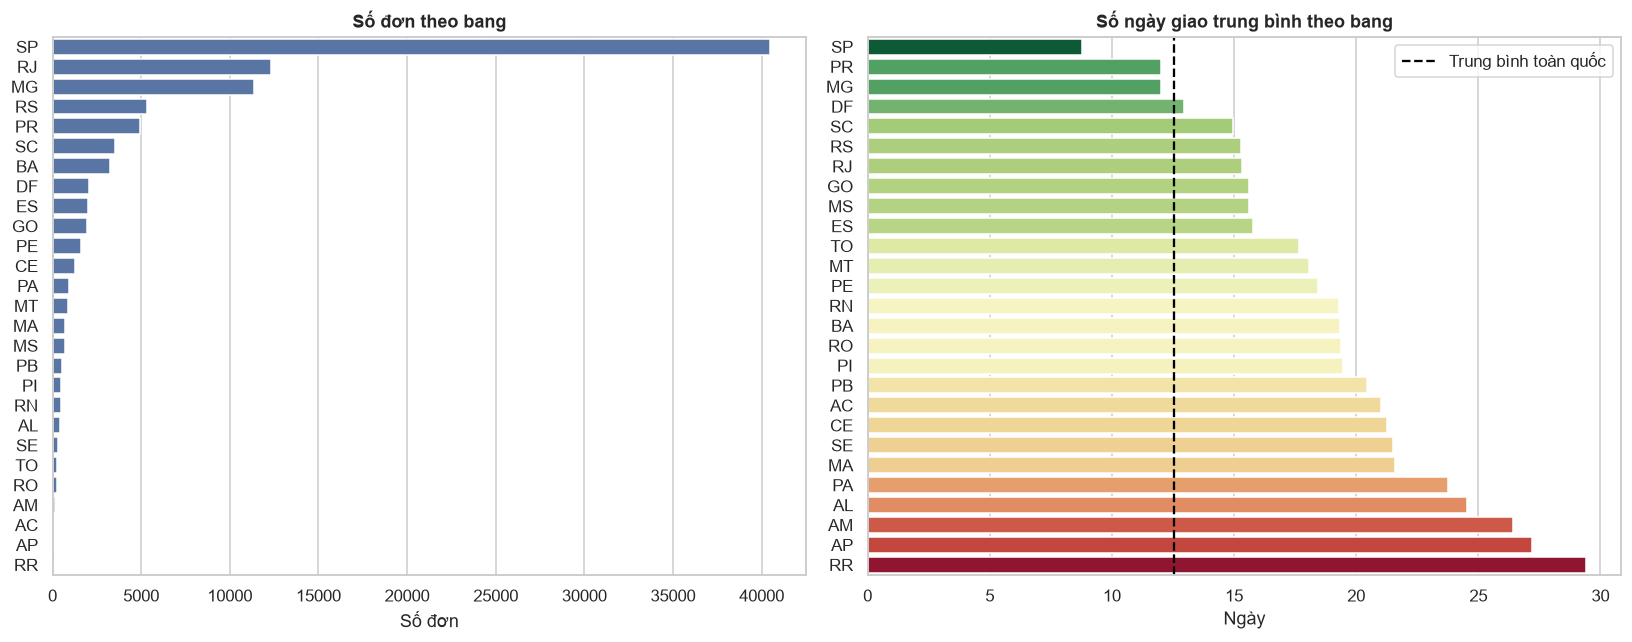

In [5]:
state = (orders.groupby('customer_state')
         .agg(n_orders=('order_id', 'count'), avg_days=('delivery_days', 'mean'), late_pct=('is_late', 'mean'))
         .sort_values('n_orders', ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(x=state['n_orders'], y=state.index, ax=axes[0], color='#4C72B0')
axes[0].set(title='Số đơn theo bang', xlabel='Số đơn', ylabel='')
s2 = state.sort_values('avg_days')
sns.barplot(x=s2['avg_days'], y=s2.index, ax=axes[1], hue=s2['avg_days'], palette='RdYlGn_r', legend=False)
axes[1].axvline(orders['delivery_days'].mean(), ls='--', color='black', label='Trung bình toàn quốc')
axes[1].set(title='Số ngày giao trung bình theo bang', xlabel='Ngày', ylabel='')
axes[1].legend()
fig.tight_layout()
save(fig, '04_state_orders_delivery')
plt.show()

## 5. Bản đồ thời gian giao hàng
Mỗi điểm là một mã zip của khách (toạ độ trung bình từ bảng geolocation sạch), màu thể hiện số ngày giao trung bình.

Định vị được 99.7% số đơn


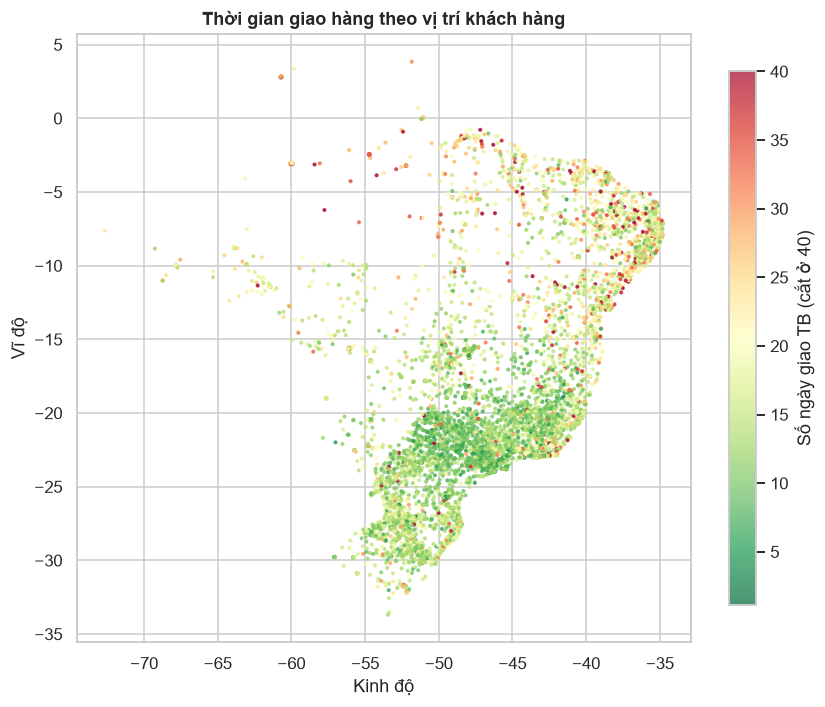

In [6]:
geo = pd.read_csv(os.path.join(PRO_DIR, 'clean_olist_geolocation_dataset.csv'),
                  dtype={'geolocation_zip_code_prefix': str})
zip_days = (orders.groupby('customer_zip_code_prefix')
            .agg(avg_days=('delivery_days', 'mean'), n_orders=('order_id', 'count'))
            .merge(geo, left_index=True, right_on='geolocation_zip_code_prefix'))
print(f'Định vị được {zip_days.n_orders.sum() / len(orders) * 100:.1f}% số đơn')

fig, ax = plt.subplots(figsize=(9, 9))
sc = ax.scatter(zip_days['geolocation_lng'], zip_days['geolocation_lat'], c=zip_days['avg_days'].clip(upper=40),
                cmap='RdYlGn_r', s=3, alpha=0.7)
fig.colorbar(sc, ax=ax, label='Số ngày giao TB (cắt ở 40)', shrink=0.7)
ax.set(title='Thời gian giao hàng theo vị trí khách hàng', xlabel='Kinh độ', ylabel='Vĩ độ')
ax.set_aspect('equal')
save(fig, '05_delivery_map')
plt.show()

## 6. Giao hàng trễ và điểm review

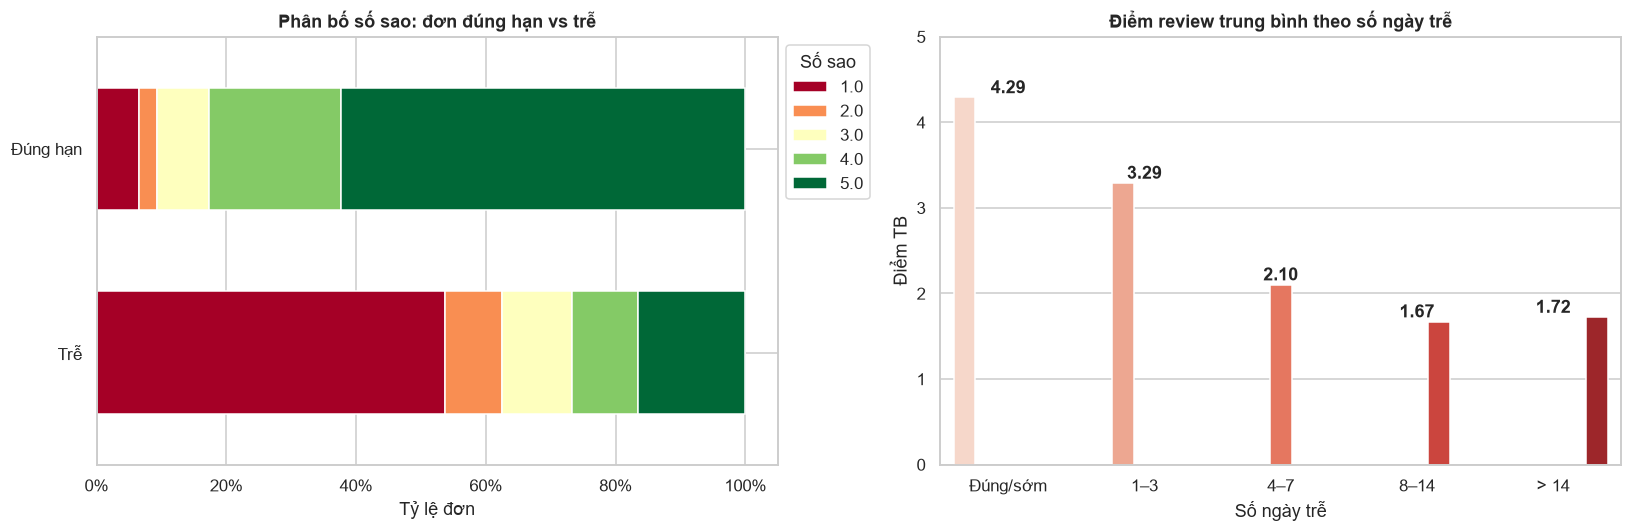

In [7]:
rv = orders.dropna(subset=['review_score']).copy()
rv['Trạng thái'] = rv['is_late'].map({False: 'Đúng hạn', True: 'Trễ'})
dist = pd.crosstab(rv['Trạng thái'], rv['review_score'], normalize='index') * 100

bins = [-np.inf, 0, 3, 7, 14, np.inf]
labels = ['Đúng/sớm', '1–3', '4–7', '8–14', '> 14']
rv['delay_group'] = pd.cut(rv['delay_days'], bins=bins, labels=labels)
by_delay = rv.groupby('delay_group', observed=True)['review_score'].mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
dist.plot(kind='barh', stacked=True, ax=axes[0], colormap='RdYlGn', width=0.6)
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter())
axes[0].set(title='Phân bố số sao: đơn đúng hạn vs trễ', xlabel='Tỷ lệ đơn', ylabel='')
axes[0].legend(title='Số sao', bbox_to_anchor=(1, 1))
sns.barplot(x=by_delay.index, y=by_delay.values, ax=axes[1], hue=by_delay.index, palette='Reds', legend=False)
for i, v in enumerate(by_delay.values):
    axes[1].text(i, v + 0.05, f'{v:.2f}', ha='center', fontweight='bold')
axes[1].set(title='Điểm review trung bình theo số ngày trễ', xlabel='Số ngày trễ', ylabel='Điểm TB', ylim=(0, 5))
fig.tight_layout()
save(fig, '06_late_vs_review')
plt.show()

## 7. Phân phối thời gian giao hàng

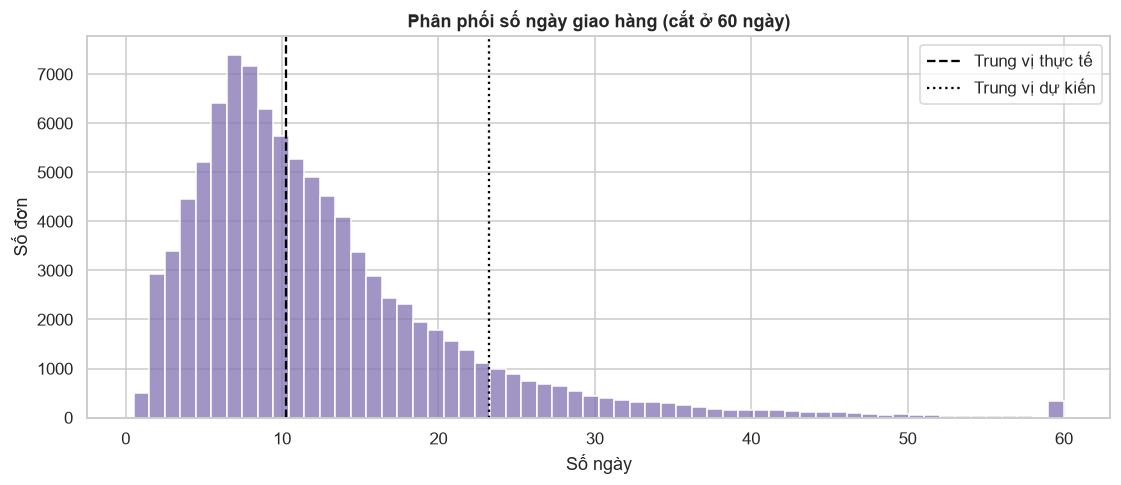

In [8]:
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.histplot(orders['delivery_days'].clip(upper=60), bins=60, ax=ax, color='#8172B2')
for q, ls in [(orders['delivery_days'].median(), '--'), (orders['estimated_days'].median(), ':')]:
    ax.axvline(q, color='black', ls=ls)
ax.legend(['Trung vị thực tế', 'Trung vị dự kiến'])
ax.set(title='Phân phối số ngày giao hàng (cắt ở 60 ngày)', xlabel='Số ngày', ylabel='Số đơn')
save(fig, '07_delivery_days_hist')
plt.show()

## 8. Hành vi thanh toán

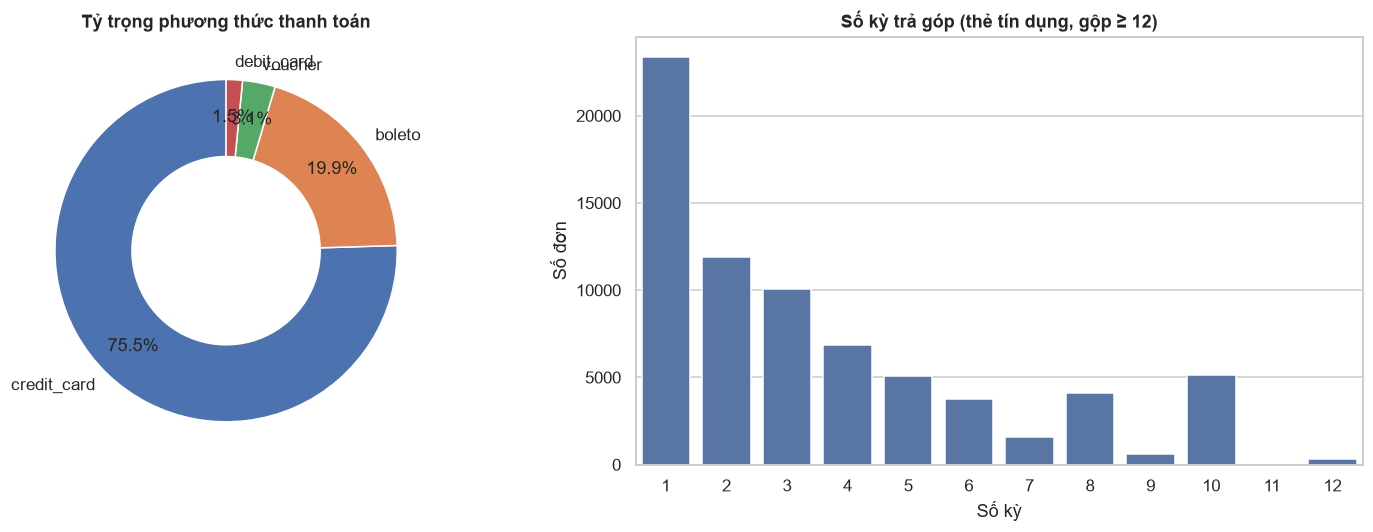

In [9]:
pay_share = orders['payment_type'].value_counts()
inst = orders.loc[orders['payment_type'] == 'credit_card', 'payment_installments'].clip(upper=12)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].pie(pay_share, labels=pay_share.index, autopct='%1.1f%%', startangle=90,
            wedgeprops={'width': 0.45}, pctdistance=0.78)
axes[0].set_title('Tỷ trọng phương thức thanh toán')
sns.countplot(x=inst.astype(int), ax=axes[1], color='#4C72B0')
axes[1].set(title='Số kỳ trả góp (thẻ tín dụng, gộp ≥ 12)', xlabel='Số kỳ', ylabel='Số đơn')
fig.tight_layout()
save(fig, '08_payment')
plt.show()

## 9. Ma trận tương quan các biến số
Dùng hệ số **Spearman** vì các biến lệch phải mạnh và `review_score` là thứ bậc.

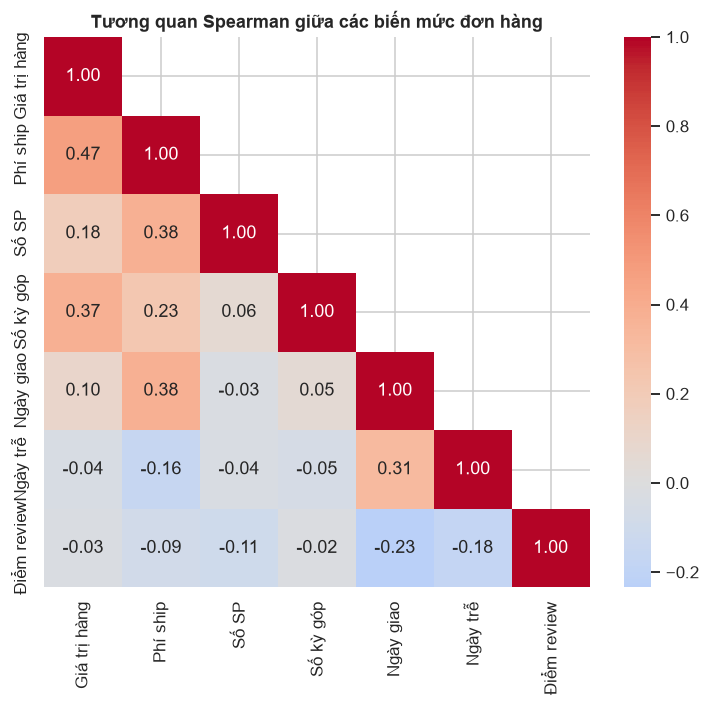

In [10]:
cols = {'product_value': 'Giá trị hàng', 'freight_value': 'Phí ship', 'n_items': 'Số SP',
        'payment_installments': 'Số kỳ góp', 'delivery_days': 'Ngày giao',
        'delay_days': 'Ngày trễ', 'review_score': 'Điểm review'}
corr = orders[list(cols)].rename(columns=cols).corr(method='spearman')

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, mask=np.triu(np.ones_like(corr, bool), 1), ax=ax)
ax.set_title('Tương quan Spearman giữa các biến mức đơn hàng')
save(fig, '09_correlation')
plt.show()

## 10. Tóm tắt insight từ biểu đồ
| **Biểu đồ** | **Insight** |
|---|---|
| Doanh thu theo tháng | Tăng trưởng mạnh suốt 2017, đỉnh Black Friday 11/2017, đi ngang ở mức cao năm 2018 |
| Heatmap thứ × giờ | Đơn tập trung 10h–22h ngày thường; cuối tuần thấp hơn rõ rệt |
| Pareto danh mục | Một nhóm nhỏ danh mục tạo phần lớn doanh thu |
| Bang & bản đồ | Đông Nam & Nam (SP, PR, MG) giao nhanh; miền Bắc / Đông Bắc giao chậm gấp 2–3 lần |
| Trễ vs review | Chỉ cần trễ vài ngày, tỷ lệ 1 sao tăng vọt; điểm TB giảm dần theo số ngày trễ |
| Thanh toán | Thẻ tín dụng áp đảo, phần lớn đơn trả góp nhiều kỳ |
| Tương quan | `Ngày trễ` và `Ngày giao` tương quan âm với `Điểm review`; `Phí ship` tăng theo `Giá trị hàng` |